# Caso 1: Clustering jerárquico con 20 Newsgroups
**Actividad 05 · Aprendizaje de Máquina · UNAP**

Qué hacemos aquí:
1. Tomamos 5 grupos de noticias del dataset *20 Newsgroups* y limpiamos el texto.
2. Pasamos cada documento a TF-IDF y lo comprimimos con LSA (`TruncatedSVD`).
3. Probamos cuatro criterios de *linkage*: `ward`, `complete`, `average` y `single`.
4. Comparamos los resultados con métricas y con los dendrogramas.
5. Interpretamos los clusters del criterio que mejor funcionó.

Nota: las etiquetas reales (el grupo de noticias) **no** se usan para agrupar, solo para evaluar al final.

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_score, silhouette_score)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

SEED = 42
os.makedirs("figuras", exist_ok=True)
os.makedirs("resultados", exist_ok=True)

## 1. Datos
Elegimos cinco temas bien distintos entre sí y 200 documentos por tema (1000 en total).
Con esto el dendrograma se puede leer y `linkage` corre sin problemas de memoria.

In [2]:
CATEGORIAS = ["rec.autos", "sci.space", "comp.graphics", "talk.politics.guns", "sci.med"]
N_POR_CATEGORIA = 200

data = fetch_20newsgroups(subset="train", categories=CATEGORIAS,
                          remove=("headers", "footers", "quotes"),
                          shuffle=True, random_state=SEED)
textos = np.array(data.data, dtype=object)
y = np.array(data.target)
nombres = list(data.target_names)

# quitamos documentos casi vacíos (muchos quedan en blanco al borrar encabezados y citas)
largo_ok = np.array([len(t.split()) >= 30 for t in textos])
textos, y = textos[largo_ok], y[largo_ok]

rng = np.random.RandomState(SEED)
idx = np.concatenate([rng.choice(np.where(y == c)[0], N_POR_CATEGORIA, replace=False)
                      for c in range(len(nombres))])
textos, y = textos[idx], y[idx]
print("Documentos:", len(textos))
print(pd.Series([nombres[i] for i in y]).value_counts())

Documentos: 1000
comp.graphics         200
rec.autos             200
sci.med               200
sci.space             200
talk.politics.guns    200
Name: count, dtype: int64


## 2. Representación: TF-IDF + LSA
TF-IDF da un vector enorme y casi vacío por documento. Lo comprimimos a 100 dimensiones con
`TruncatedSVD` (LSA) y normalizamos, así la distancia euclidiana equivale a comparar ángulos (coseno).

In [3]:
vec = TfidfVectorizer(stop_words="english", max_df=0.5, min_df=3,
                      max_features=5000, sublinear_tf=True)
tfidf = vec.fit_transform(textos)
terminos = vec.get_feature_names_out()

svd = TruncatedSVD(n_components=100, random_state=SEED)
X = normalize(svd.fit_transform(tfidf))
var_lsa = float(svd.explained_variance_ratio_.sum())
print("TF-IDF:", tfidf.shape, "| LSA:", X.shape, "| varianza explicada: %.1f%%" % (100 * var_lsa))

TF-IDF: (1000, 5000) | LSA: (1000, 100) | varianza explicada: 25.3%


## 3. Cuatro criterios de linkage
- **ward**: fusiona los clusters que menos aumentan la varianza interna.
- **complete**: distancia entre clusters = la mayor distancia entre dos de sus puntos.
- **average**: promedio de todas las distancias entre puntos de ambos clusters.
- **single**: la menor distancia entre dos puntos (propenso al "efecto cadena").

Cortamos cada árbol en K = 5 clusters (los 5 temas) y medimos qué tan bien coinciden con los grupos reales.

In [4]:
METODOS = ["ward", "complete", "average", "single"]
K = len(nombres)
d_euclid = pdist(X)

Z = {}
res = {}
for m in METODOS:
    Z[m] = linkage(X, method=m)
    et = fcluster(Z[m], K, criterion="maxclust")
    tam = np.bincount(et)[1:]
    res[m] = {
        "ARI": float(adjusted_rand_score(y, et)),
        "NMI": float(normalized_mutual_info_score(y, et)),
        "homogeneidad": float(homogeneity_score(y, et)),
        "silhouette": float(silhouette_score(X, et)) if len(set(et)) > 1 else float("nan"),
        "cofenetica": float(cophenet(Z[m], d_euclid)[0]),
        "pct_cluster_mayor": float(100 * tam.max() / len(et)),
        "n_clusters": int(len(set(et))),
    }
tabla = pd.DataFrame(res).T
tabla

,ARI,NMI,homogeneidad,silhouette,cofenetica,pct_cluster_mayor,n_clusters
ward,0.259712,0.365622,0.334718,0.031935,0.250786,47.5,5.0
complete,0.031122,0.048901,0.048325,0.005212,0.410043,31.1,5.0
average,0.005867,0.083668,0.050848,0.018028,0.530708,92.8,5.0
single,0.000010,0.011294,0.005825,-0.033835,0.266561,99.3,5.0


Mejor criterio según ARI: ward


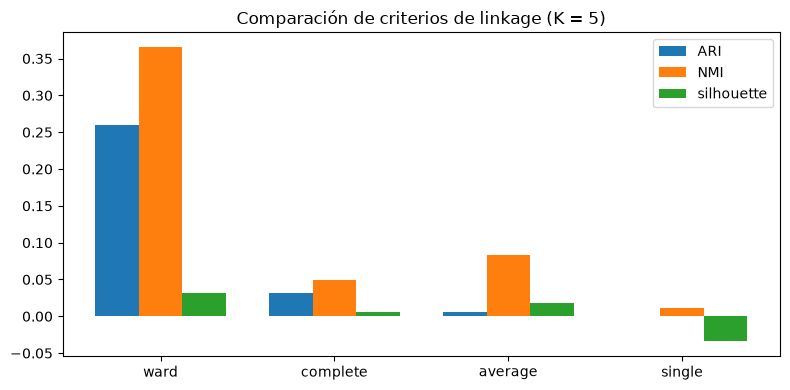

In [5]:
mejor = max(METODOS, key=lambda m: res[m]["ARI"])
print("Mejor criterio según ARI:", mejor)

fig, ax = plt.subplots(figsize=(8, 4))
ancho = 0.25
x = np.arange(len(METODOS))
for j, met in enumerate(["ARI", "NMI", "silhouette"]):
    ax.bar(x + (j - 1) * ancho, [res[m][met] for m in METODOS], ancho, label=met)
ax.set_xticks(x); ax.set_xticklabels(METODOS)
ax.set_title("Comparación de criterios de linkage (K = 5)")
ax.legend(); plt.tight_layout()
plt.savefig("figuras/caso1_metricas.png", dpi=150); plt.show()

## 4. Dendrogramas
Mostramos solo los últimos 25 nodos fusionados (`truncate_mode='lastp'`); el número entre paréntesis
es cuántos documentos quedaron dentro de esa rama. La línea punteada es el corte para K = 5.

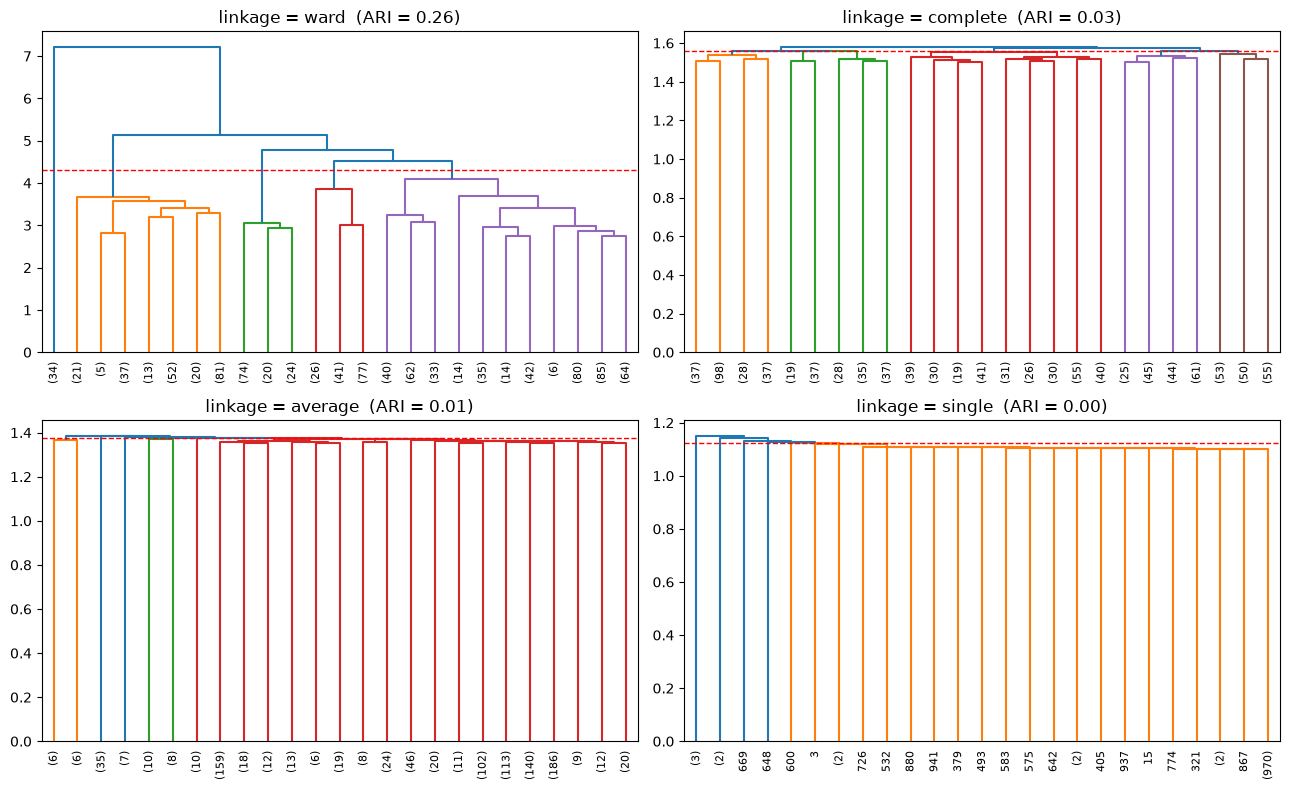

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, m in zip(axes.ravel(), METODOS):
    Zm = Z[m]
    corte = (Zm[-K, 2] + Zm[-(K - 1), 2]) / 2
    dendrogram(Zm, truncate_mode="lastp", p=25, ax=ax, color_threshold=corte,
               leaf_rotation=90, leaf_font_size=8, show_leaf_counts=True)
    ax.axhline(corte, ls="--", c="red", lw=1)
    ax.set_title(f"linkage = {m}  (ARI = {res[m]['ARI']:.2f})")
plt.tight_layout()
plt.savefig("figuras/caso1_dendrogramas.png", dpi=150); plt.show()

## 5. ¿Cuántos clusters conviene? (sin usar etiquetas)
Con el mejor criterio, miramos el coeficiente de silueta para distintos cortes del árbol.

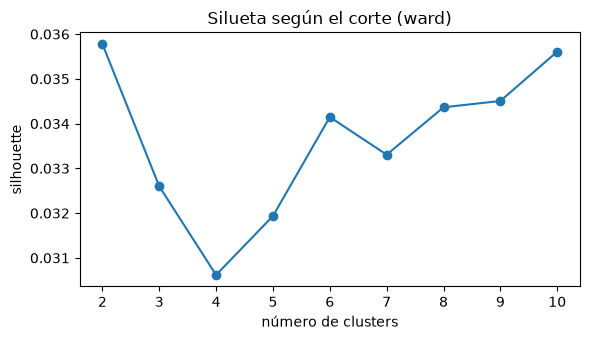

In [7]:
ks = list(range(2, 11))
sil = {k: float(silhouette_score(X, fcluster(Z[mejor], k, criterion="maxclust"))) for k in ks}
plt.figure(figsize=(6, 3.5))
plt.plot(ks, list(sil.values()), "o-")
plt.xlabel("número de clusters"); plt.ylabel("silhouette")
plt.title(f"Silueta según el corte ({mejor})")
plt.tight_layout(); plt.savefig("figuras/caso1_silhouette.png", dpi=150); plt.show()

## 6. Interpretación de los clusters del mejor criterio
Cruzamos clusters con los grupos reales y sacamos las palabras con más peso TF-IDF de cada cluster.

In [8]:
et = fcluster(Z[mejor], K, criterion="maxclust")
real = pd.Series([nombres[i] for i in y], name="grupo real")
ct = pd.crosstab(pd.Series(et, name="cluster"), real)
print(ct)

clusters = []
for c in sorted(set(et)):
    m = et == c
    prom = np.asarray(tfidf[m].mean(axis=0)).ravel()
    top = [terminos[i] for i in prom.argsort()[::-1][:8]]
    fila = ct.loc[c]
    clusters.append({"cluster": int(c), "tamano": int(m.sum()),
                     "dominante": str(fila.idxmax()),
                     "pureza": float(fila.max() / fila.sum()),
                     "terminos": top})
pd.DataFrame(clusters)

grupo real  comp.graphics  rec.autos  sci.med  sci.space  talk.politics.guns
cluster                                                                     
1                       0          0       34          0                   0
2                     164         13       21         22                   9
3                       7          2        4         97                   8
4                       1         12        2          5                 124
5                      28        173      139         76                  59


,cluster,tamano,dominante,pureza,terminos
0,1,34,sci.med,1.000000,"[shameful, cadre, dsl, chastity, skepticism, n..."
1,2,229,comp.graphics,0.716157,"[thanks, graphics, software, files, program, k..."
2,3,118,sci.space,0.822034,"[space, nasa, orbit, launch, moon, use, lunar,..."
3,4,144,talk.politics.guns,0.861111,"[people, gun, fbi, law, don, government, right..."
4,5,475,rec.autos,0.364211,"[car, don, just, like, know, good, time, think]"


In [9]:
pureza_total = float(sum(ct.loc[c].max() for c in ct.index) / ct.values.sum())
print("Pureza global (mejor linkage): %.1f%%" % (100 * pureza_total))

with open("resultados/caso1.json", "w", encoding="utf-8") as f:
    json.dump({
        "categorias": nombres, "n_docs": int(len(textos)), "k": K,
        "tfidf_shape": list(tfidf.shape), "lsa_dim": 100, "var_lsa": var_lsa,
        "metodos": res, "mejor": mejor, "silhouette_k": sil,
        "pureza_global": pureza_total,
        "crosstab": {str(a): {str(b): int(v) for b, v in row.items()} for a, row in ct.iterrows()},
        "clusters": clusters,
    }, f, ensure_ascii=False, indent=2)
print("Resultados guardados en resultados/caso1.json")

Pureza global (mejor linkage): 59.2%
Resultados guardados en resultados/caso1.json


## Conclusión del caso
- `ward` fue el mejor de los criterios comparados, pero el acuerdo con los grupos reales fue modesto.
- En esta ejecución, `average` y `single` dejaron casi todos los documentos en un mismo cluster.
- Algunos clusters de `ward` se reconocen por tema; otros mezclan documentos y términos genéricos.